# Session 7 — Homework

## 0. Setup

In [10]:
# PURPOSE: libraries, project root, device, switches.
import sys, time, json, copy, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score, recall_score, ConfusionMatrixDisplay, classification_report

# ---- switches ----
RUN_SEEDS = True            # train the full fine-tune with 2 extra seeds -> mean +- std
EXTRA_SEEDS = [1, 2]
RUN_EFFICIENTNET = True     # extra backbone: EfficientNet-B0 (downloads ~20 MB the first time)
RETRAIN = False             # True = ignore saved weights and train everything again

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/ComputerVision_SpeechRecognition_Course")  # <- your Drive path
else:
    start = Path.cwd().resolve()
    candidates = [p for p in [start, *start.parents]
                  if (p / "data" / "milk10k" / "metadata.csv").is_file() or (p / "common" / "config.py").is_file()]
    if not candidates:
        raise FileNotFoundError("Run this notebook from inside the project folder (the one with data/ and common/).")
    ROOT = candidates[0]
sys.path.insert(0, str(ROOT))

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("root:", ROOT, "| device:", device, "| torch", torch.__version__)

def seed_all(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(0)

OUT = ROOT / "outputs" / "session_07_hw"
OUT.mkdir(parents=True, exist_ok=True)
RES_PATH = OUT / "results.json"
results = json.load(open(RES_PATH)) if RES_PATH.exists() else {}
def save_results():
    json.dump(results, open(RES_PATH, "w"), indent=2)
count = lambda m: sum(p.numel() for p in m.parameters())

root: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification | device: mps | torch 2.14.0


## 1. Data: the same split as Sessions 5–6, verified

The cell tries three sources, in this order, and uses the **first one whose class counts match the slides**:
1. `common.milk10k.make_splits` (the course helper, if it works),
2. a split saved in your `splits/` folder (CSV or JSON with lesion or image ids),
3. a fallback built here with `StratifiedGroupKFold` (not identical to earlier sessions).

If none matches, the notebook still runs but prints a loud warning, because scores would then not be comparable with Sessions 5–6.

In [11]:
# PURPOSE: load the split from the first source that reproduces the slides' class counts.
CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}
DATA = ROOT / "data" / "milk10k"
# Class counts [Benign, Indeterminate, Malignant] printed in the Session 5 and 6 slides
EXPECTED = {"train": [1016, 83, 2494], "val": [170, 17, 412]}

df_all = pd.read_csv(DATA / "metadata.csv")
derm = df_all[df_all["image_type"] == "dermoscopic"].reset_index(drop=True)   # one image per lesion

try:
    from common import config
    image_path = config.image_path
except Exception:
    image_path = lambda isic_id: DATA / "images" / f"{isic_id}.jpg"

def class_counts(d):
    return [int((d["diagnosis_1"] == c).sum()) for c in CLASSES]

def load_saved_split(splits_dir, derm):
    """Read a split saved in splits/. Supports one CSV/JSON with a split column,
    {"train": [...], "val": [...], "test": [...]} JSON, or separate train/val/test CSV/TXT files.
    Ids can be lesion_id or isic_id."""
    norm = {"train": "train", "training": "train", "val": "val", "valid": "val", "validation": "val",
            "test": "test", "testing": "test"}
    id_cols, split_cols = ["lesion_id", "isic_id", "image_id", "id"], ["split", "set", "subset", "partition"]
    def split_from_name(name):
        low = name.lower()
        found = {g for g, tokens in {"train": ["train"], "val": ["val"], "test": ["test"]}.items()
                 if any(t in low for t in tokens)}
        return found.pop() if len(found) == 1 else None
    assign, used = {}, []
    for p in sorted(Path(splits_dir).rglob("*")):
        if not p.is_file(): continue
        suf = p.suffix.lower()
        try:
            if suf == ".csv":
                t = pd.read_csv(p); cols = {c.lower(): c for c in t.columns}
                idc = next((cols[c] for c in id_cols if c in cols), None)
                if idc is None: continue
                spc = next((cols[c] for c in split_cols if c in cols), None)
                if spc is not None:
                    m = {str(i): norm.get(str(s).strip().lower()) for i, s in zip(t[idc], t[spc])}
                else:
                    s = split_from_name(p.stem)
                    if s is None: continue
                    m = {str(i): s for i in t[idc]}
            elif suf == ".json":
                obj = json.load(open(p))
                if not isinstance(obj, dict): continue
                if all(isinstance(v, list) for v in obj.values()):
                    m = {str(i): norm.get(k.strip().lower()) for k, v in obj.items() for i in v}
                else:
                    m = {str(k): norm.get(str(v).strip().lower()) for k, v in obj.items()}
            elif suf == ".txt":
                s = split_from_name(p.stem)
                if s is None: continue
                m = {line.strip(): s for line in open(p) if line.strip()}
            else:
                continue
        except Exception:
            continue
        m = {k: v for k, v in m.items() if v}
        if m:
            assign.update(m); used.append(p.name)
    if not used:
        raise FileNotFoundError(f"no readable split files in {splits_dir}")
    for key in ["lesion_id", "isic_id"]:
        s = derm[key].astype(str).map(assign)
        if s.notna().mean() > 0.99:
            break
    else:
        raise ValueError("ids found in splits/ do not match metadata.csv")
    print("   saved split read from:", used)
    parts = [derm[s == name].reset_index(drop=True) for name in ["train", "val", "test"]]
    if any(len(p) == 0 for p in parts):
        raise ValueError("one of train/val/test is empty in the saved split")
    return parts

def from_common():
    from common import milk10k
    df, gt = milk10k.load_metadata(), milk10k.load_gt()
    return [d[d["image_type"] == "dermoscopic"].reset_index(drop=True) for d in milk10k.make_splits(df, gt, seed=0)]

def from_saved():
    return load_saved_split(ROOT / "splits", derm)

def from_fallback():
    from sklearn.model_selection import StratifiedGroupKFold
    y_all = derm["diagnosis_1"].map(to_int)
    tv, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(derm, y_all, derm["lesion_id"]))
    rest = derm.iloc[tv].reset_index(drop=True)
    tr, va = next(StratifiedGroupKFold(7, shuffle=True, random_state=0).split(rest, rest["diagnosis_1"].map(to_int), rest["lesion_id"]))
    return [rest.iloc[tr].reset_index(drop=True), rest.iloc[va].reset_index(drop=True), derm.iloc[te].reset_index(drop=True)]

chosen, first_ok = None, None
for label, fn in [("common.milk10k.make_splits", from_common), ("saved split in splits/", from_saved), ("FALLBACK split built here", from_fallback)]:
    try:
        parts = fn()
    except Exception as e:
        print(f"- {label}: not usable ({type(e).__name__}: {str(e)[:110]})")
        continue
    ok = class_counts(parts[0]) == EXPECTED["train"] and class_counts(parts[1]) == EXPECTED["val"]
    print(f"- {label}: train {class_counts(parts[0])} val {class_counts(parts[1])} -> {'MATCHES the slides' if ok else 'does not match the slides'}")
    if first_ok is None: first_ok = (label, parts)
    if ok:
        chosen = (label, parts); break

if chosen is None:
    print("\n!!! WARNING: no split reproduces the class counts of Sessions 5-6. Scores will NOT be strictly comparable with them.")
    chosen = first_ok
SPLIT_SOURCE, (train_df, val_df, test_df) = chosen[0], chosen[1]
print("\nsplit used:", SPLIT_SOURCE)
print("sizes train/val/test:", len(train_df), len(val_df), len(test_df), "(slides: 3593 / 599 / 1048)")
assert not set(train_df.lesion_id) & set(val_df.lesion_id) and not set(train_df.lesion_id) & set(test_df.lesion_id) and not set(val_df.lesion_id) & set(test_df.lesion_id), "lesion leakage!"
print(pd.DataFrame({n: d["diagnosis_1"].value_counts() for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}))

# --- fingerprint of the split: if it changed, old weights/scores are stale and are deleted ---
SPLIT_HASH = hashlib.md5("|".join(f"{n}:{','.join(sorted(d['lesion_id']))}" for n, d in
                                   [("train", train_df), ("val", val_df), ("test", test_df)]).encode()).hexdigest()
hash_file = OUT / "split_hash.txt"
if not (hash_file.exists() and hash_file.read_text().strip() == SPLIT_HASH):
    old = [p for p in OUT.iterdir() if p.is_file() and p.suffix in {".pt", ".npy", ".json", ".csv", ".png"}]
    for p in old: p.unlink()
    results.clear()
    print(f"split fingerprint changed or new: removed {len(old)} old output files in {OUT.name}/ (they belonged to another split)")
hash_file.write_text(SPLIT_HASH)

- common.milk10k.make_splits: not usable (ImportError: cannot import name 'milk10k' from 'common' (/Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-L)
   saved split read from: ['test_split.csv', 'train_split.csv', 'val_split.csv']
- saved split in splits/: train [1058, 89, 2595] val [212, 17, 520] -> does not match the slides
- FALLBACK split built here: train [1017, 84, 2492] val [169, 15, 415] -> does not match the slides

!!! WARNING: no split reproduces the class counts of Sessions 5-6. Scores will NOT be strictly comparable with them.

split used: saved split in splits/
sizes train/val/test: 3742 749 749 (slides: 3593 / 599 / 1048)
               train  val  test
diagnosis_1                    
Malignant       2595  520   519
Benign          1058  212   213
Indeterminate     89   17    17


32

In [12]:
# PURPOSE: decode every image once as uint8 224x224 and keep it in memory (cached on disk).
# The cache is only used if it matches THIS split; otherwise a new one is built.
cache_dir = ROOT / "session_07_cnns" / "_output"
cache_dir.mkdir(parents=True, exist_ok=True)
SPLITS = {"train": train_df, "val": val_df, "test": test_df}

def cache_matches(d):
    for name, split in SPLITS.items():
        if f"X_{name}" not in d or len(d[f"X_{name}"]) != len(split): return False
        if not np.array_equal(d[f"y_{name}"].numpy(), split["diagnosis_1"].map(to_int).to_numpy()): return False
        if f"ids_{name}" in d and list(d[f"ids_{name}"]) != list(split["isic_id"]): return False   # new caches store the image ids
    return True

data = None
for fname in ["images_224.pt", "images_224_hw.pt"]:
    p = cache_dir / fname
    if p.exists():
        d = torch.load(p)
        if cache_matches(d):
            data = d; print("using image cache:", fname); break
        print("ignoring image cache (different split or order):", fname)
if data is None:
    t0 = time.perf_counter(); data = {}
    for name, split in SPLITS.items():
        X = torch.empty((len(split), 3, 224, 224), dtype=torch.uint8)
        for i, isic_id in enumerate(split["isic_id"]):
            img = Image.open(image_path(isic_id)).convert("RGB").resize((224, 224))
            X[i] = torch.from_numpy(np.array(img)).permute(2, 0, 1)
        data[f"X_{name}"] = X
        data[f"y_{name}"] = torch.tensor(split["diagnosis_1"].map(to_int).to_numpy())
        data[f"ids_{name}"] = list(split["isic_id"])
    torch.save(data, cache_dir / "images_224_hw.pt")
    print(f"built image cache images_224_hw.pt in {time.perf_counter() - t0:.0f} s")
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]
assert cache_matches(data), "images and labels do not match the split"
print(X_train.shape, X_train.dtype, torch.bincount(y_train).tolist())

ignoring image cache (different split or order): images_224.pt
using image cache: images_224_hw.pt
torch.Size([3742, 3, 224, 224]) torch.uint8 [1058, 89, 2595]


## 2. Shared toolkit (same training loop as Session 7)

In [13]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
def prep(xb):
    return (xb.to(device).float() / 255 - MEAN) / STD

def augment(xb):
    n = xb.size(0)
    flip_h = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    xb = torch.where(flip_h, xb.flip(3), xb)
    flip_v = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    return torch.where(flip_v, xb.flip(2), xb)

class_weights = (len(y_train) / (3 * torch.bincount(y_train).float())).to(device)

@torch.no_grad()
def predict(model, X, batch_size=128):
    model.eval()
    return torch.cat([model(prep(X[i:i + batch_size])).argmax(1).cpu() for i in range(0, len(X), batch_size)])

@torch.no_grad()
def probs(model, X, batch_size=128):
    model.eval()
    return torch.cat([F.softmax(model(prep(X[i:i + batch_size])), 1).cpu() for i in range(0, len(X), batch_size)])

def fit(model, params, epochs, lr, batch_size=64, aug=True):
    """Session 6/7 loop. `params` may be a list of tensors or a list of param-group dicts."""
    model.to(device)
    optimizer = torch.optim.Adam(params, lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history, best = [], {"f1": -1}
    for epoch in range(epochs):
        model.train(); t0, total = time.perf_counter(), 0.0
        order = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch_size):
            idx = order[i:i + batch_size]
            xb, yb = prep(X_train[idx]), y_train[idx].to(device)
            if aug: xb = augment(xb)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        f1 = f1_score(y_val, predict(model, X_val), average="macro")
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_f1": f1})
        print(f"epoch {epoch} loss {total / len(X_train):.3f} val macro-F1 {f1:.3f} ({time.perf_counter() - t0:.0f} s)")
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])      # early stopping: keep the best epoch (chosen on VALIDATION)
    return pd.DataFrame(history).set_index("epoch"), best

def bootstrap_ci(y_true, y_pred, n=1000, seed=0):
    """95% bootstrap interval of macro-F1, resampling lesions."""
    rng = np.random.default_rng(seed); y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    s = [f1_score(y_true[i], y_pred[i], average="macro")
         for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return [float(v) for v in np.percentile(s, [2.5, 97.5])]

# --- bookkeeping: validation score for every model; test score only once, in section 5 ---
predictors, prob_fns = {}, {}   # name -> function(split) -> predictions / probabilities
XS = {"val": X_val, "test": X_test}

def train_or_load(name, model, params, epochs, lr, n_trainable=None):
    ckpt = OUT / f"{name}.pt"
    model.to(device)
    if ckpt.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device)); print(f"[{name}] loaded saved weights")
    else:
        t0 = time.perf_counter()
        hist, best = fit(model, params, epochs, lr)
        torch.save(model.state_dict(), ckpt)
        results.setdefault(name, {}).update(best_epoch=int(best["epoch"]), sec_per_epoch=(time.perf_counter() - t0) / epochs)
        hist.to_csv(OUT / f"{name}_history.csv")
    predictors[name] = lambda split, m=model: predict(m, XS[split])
    prob_fns[name] = lambda split, m=model: probs(m, XS[split])
    pv = predictors[name]("val")
    results.setdefault(name, {}).update(
        val_f1=float(f1_score(y_val, pv, average="macro")),
        val_recall=[float(r) for r in recall_score(y_val, pv, average=None, labels=[0, 1, 2])],
        params_trained=int(n_trainable if n_trainable is not None else count(model)))
    save_results()
    print(f"[{name}] val macro-F1 = {results[name]['val_f1']:.3f}")

## 3. Models of Session 7 (rebuilt, so the scoreboard is reproducible)

| name | what is trained |
|---|---|
| `scratch_cnn` | SimpleCNN from random weights |
| `resnet18_frozen_head` | frozen ResNet-18 + new `Linear(512,3)` on cached embeddings |
| `resnet18_layer4` | layer4 + head (lr 1e-4) |
| `resnet18_layer3_4` | layer3 + layer4 + head (lr 1e-4), the mini challenge |
| `resnet18_full` | **strategy 3: every layer**, with discriminative learning rates |
| `resnet18_full_seed1/2` | the same, with other seeds (error bars) |
| `efficientnet_b0_full` | extra backbone, every layer |

In [14]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 56 * 56, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

seed_all(0)
scratch = SimpleCNN()
train_or_load("scratch_cnn", scratch, scratch.parameters(), epochs=10, lr=1e-3)

[scratch_cnn] loaded saved weights
[scratch_cnn] val macro-F1 = 0.534


In [15]:
# Frozen ResNet-18 as feature extractor (512 learned numbers per lesion) + linear head.
seed_all(0)
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = nn.Identity(); backbone.to(device).eval()

@torch.no_grad()
def embed(X, batch_size=128):
    return torch.cat([backbone(prep(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)])

emb_cache = OUT / "embeddings.pt"
if emb_cache.exists() and not RETRAIN:
    F_train, F_val, F_test = torch.load(emb_cache)
else:
    F_train, F_val, F_test = embed(X_train), embed(X_val), embed(X_test)
    torch.save((F_train, F_val, F_test), emb_cache)

from torch.utils.data import DataLoader, TensorDataset
head = nn.Linear(512, 3).to(device)
head_ckpt = OUT / "resnet18_frozen_head.pt"
if head_ckpt.exists() and not RETRAIN:
    head.load_state_dict(torch.load(head_ckpt, map_location=device)); print("[frozen head] loaded")
else:
    opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    loader = DataLoader(TensorDataset(F_train, y_train), batch_size=64, shuffle=True)
    best_f1, best_state = -1, None
    for epoch in range(25):
        head.train()
        for fb, yb in loader:
            opt.zero_grad(); loss_fn(head(fb.to(device)), yb.to(device)).backward(); opt.step()
        with torch.no_grad():
            f1 = f1_score(y_val, head(F_val.to(device)).argmax(1).cpu(), average="macro")
        if f1 > best_f1: best_f1, best_state = f1, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state); torch.save(head.state_dict(), head_ckpt)

feats = {"val": F_val, "test": F_test}
@torch.no_grad()
def head_logits(split):
    head.eval(); return head(feats[split].to(device)).cpu()
predictors["resnet18_frozen_head"] = lambda split: head_logits(split).argmax(1)
prob_fns["resnet18_frozen_head"] = lambda split: F.softmax(head_logits(split), 1)
pv = predictors["resnet18_frozen_head"]("val")
results["resnet18_frozen_head"] = {**results.get("resnet18_frozen_head", {}),
    "val_f1": float(f1_score(y_val, pv, average="macro")),
    "val_recall": [float(r) for r in recall_score(y_val, pv, average=None, labels=[0, 1, 2])],
    "params_trained": count(head)}
save_results()
print("[resnet18_frozen_head] val macro-F1 =", round(results["resnet18_frozen_head"]["val_f1"], 3), "(Session 7 slides: ~0.632)")

[frozen head] loaded
[resnet18_frozen_head] val macro-F1 = 0.583 (Session 7 slides: ~0.632)


In [16]:
def make_resnet(trainable_prefixes):
    """Fresh pretrained ResNet-18, new 3-class head, only layers starting with these prefixes are trained."""
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 3)
    for name, p in m.named_parameters():
        p.requires_grad = any(name.startswith(pref) for pref in trainable_prefixes)
    trainable = [p for p in m.parameters() if p.requires_grad]
    return m, trainable, sum(p.numel() for p in trainable)

seed_all(0)
m4, tr4, n4 = make_resnet(["layer4", "fc"])
print(f"layer4 + fc: training {n4:,} of {count(m4):,} parameters")
train_or_load("resnet18_layer4", m4, tr4, epochs=6, lr=1e-4, n_trainable=n4)

layer4 + fc: training 8,395,267 of 11,178,051 parameters
[resnet18_layer4] loaded saved weights
[resnet18_layer4] val macro-F1 = 0.630


### Mini challenge (Section 11): also unfreeze `layer3`

In [17]:
seed_all(0)
m34, tr34, n34 = make_resnet(["layer3", "layer4", "fc"])
print(f"layer3 + layer4 + fc: training {n34:,} of {count(m34):,} parameters")
train_or_load("resnet18_layer3_4", m34, tr34, epochs=6, lr=1e-4, n_trainable=n34)
for k in ["resnet18_layer4", "resnet18_layer3_4"]:
    r = results[k]; print(f"{k:20s} params {r['params_trained']:>10,} | {r.get('sec_per_epoch', float('nan')):5.1f} s/epoch | val macro-F1 {r['val_f1']:.3f}")

layer3 + layer4 + fc: training 10,494,979 of 11,178,051 parameters
[resnet18_layer3_4] loaded saved weights
[resnet18_layer3_4] val macro-F1 = 0.637
resnet18_layer4      params  8,395,267 |   9.4 s/epoch | val macro-F1 0.630
resnet18_layer3_4    params 10,494,979 |  12.0 s/epoch | val macro-F1 0.637


## 4. Strategy 3, fine-tune the whole network

All 11.2 M weights are trained, but not at the same speed. Early layers hold generic edges and colours learned from 1.28 M photos, so they get a **tiny** learning rate; layer4 gets a moderate one; the brand-new head gets the largest. This is *discriminative learning rates*, and it limits the risk of destroying good pretrained filters with only 3,593 lesions.

In [18]:
def full_groups(m):
    return [
        {"params": [*m.conv1.parameters(), *m.bn1.parameters(), *m.layer1.parameters(), *m.layer2.parameters()], "lr": 1e-5},
        {"params": m.layer3.parameters(), "lr": 3e-5},
        {"params": m.layer4.parameters(), "lr": 1e-4},
        {"params": m.fc.parameters(),     "lr": 1e-3},
    ]

ALL_LAYERS = ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]
seed_all(0)
mfull, _, _ = make_resnet(ALL_LAYERS)
nfull = count(mfull)
print(f"training all {nfull:,} parameters")
train_or_load("resnet18_full", mfull, full_groups(mfull), epochs=8, lr=1e-4, n_trainable=nfull)

training all 11,178,051 parameters
[resnet18_full] loaded saved weights
[resnet18_full] val macro-F1 = 0.660


### 4b. Error bars: the same fine-tune with other seeds

In [19]:
if RUN_SEEDS:
    for s in EXTRA_SEEDS:
        seed_all(s)
        ms, _, _ = make_resnet(ALL_LAYERS)
        train_or_load(f"resnet18_full_seed{s}", ms, full_groups(ms), epochs=8, lr=1e-4, n_trainable=count(ms))
else:
    print("RUN_SEEDS = False: skipped")

[resnet18_full_seed1] loaded saved weights
[resnet18_full_seed1] val macro-F1 = 0.631
[resnet18_full_seed2] loaded saved weights
[resnet18_full_seed2] val macro-F1 = 0.646


### 4c. Extra backbone: EfficientNet-B0 (compound-scaled MBConv network)

In [20]:
if RUN_EFFICIENTNET:
    from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
    seed_all(0)
    eff = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    eff.classifier[1] = nn.Linear(eff.classifier[1].in_features, 3)
    eff_groups = [{"params": eff.features.parameters(), "lr": 1e-4},
                  {"params": eff.classifier.parameters(), "lr": 1e-3}]
    print(f"EfficientNet-B0: training all {count(eff):,} parameters")
    train_or_load("efficientnet_b0_full", eff, eff_groups, epochs=8, lr=1e-4, n_trainable=count(eff))
else:
    print("RUN_EFFICIENTNET = False: skipped")

EfficientNet-B0: training all 4,011,391 parameters
[efficientnet_b0_full] loaded saved weights
[efficientnet_b0_full] val macro-F1 = 0.680


In [21]:
def make_effnet():
    from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
    m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m, [{"params": m.features.parameters(), "lr": 1e-4}, {"params": m.classifier.parameters(), "lr": 1e-3}]

if RUN_EFFICIENTNET and RUN_SEEDS:
    for s in EXTRA_SEEDS:
        seed_all(s); m, g = make_effnet()
        train_or_load(f"efficientnet_b0_full_seed{s}", m, g, epochs=8, lr=1e-4, n_trainable=count(m))

epoch 0 loss 0.844 val macro-F1 0.546 (48 s)
epoch 1 loss 0.641 val macro-F1 0.563 (47 s)
epoch 2 loss 0.492 val macro-F1 0.582 (48 s)
epoch 3 loss 0.399 val macro-F1 0.629 (47 s)
epoch 4 loss 0.346 val macro-F1 0.613 (47 s)
epoch 5 loss 0.306 val macro-F1 0.627 (47 s)
epoch 6 loss 0.258 val macro-F1 0.659 (47 s)
epoch 7 loss 0.216 val macro-F1 0.670 (47 s)
[efficientnet_b0_full_seed1] val macro-F1 = 0.670
epoch 0 loss 0.870 val macro-F1 0.497 (47 s)
epoch 1 loss 0.639 val macro-F1 0.561 (47 s)
epoch 2 loss 0.507 val macro-F1 0.580 (48 s)
epoch 3 loss 0.401 val macro-F1 0.617 (49 s)
epoch 4 loss 0.345 val macro-F1 0.691 (48 s)
epoch 5 loss 0.289 val macro-F1 0.665 (57 s)
epoch 6 loss 0.244 val macro-F1 0.670 (75 s)
epoch 7 loss 0.248 val macro-F1 0.641 (394 s)
[efficientnet_b0_full_seed2] val macro-F1 = 0.691


## 5. Scoreboard (Sessions 5–7)

In [22]:
# >>> EDIT HERE: numbers from your own Session 5 and 6 notebooks (macro-F1). None = not filled in yet.

# Session 5 results: actual values from the Session 5 scoreboard
PRIOR = {
    "Session 5 · logistic regression": {
        "val_f1": 0.451,
        "test_f1": 0.437
    },
    "Session 5 · kNN (k=5)": {
        "val_f1": 0.486,
        "test_f1": 0.448
    },
    "Session 5 · random forest": {
        "val_f1": 0.560,
        "test_f1": 0.503
    },
    "Session 6 · MLP (33 features)": {
        "val_f1": None,
        "test_f1": None
    },
}

for p in [ROOT / "outputs" / "scoreboard.csv", ROOT / "reports" / "scoreboard.csv", ROOT / "notebooks" / "outputs" / "scoreboard.csv"]:
    if p.exists():
        sb = pd.read_csv(p); print("loaded", p)
        for _, r in sb.iterrows(): PRIOR[r["model"]] = {"val_f1": r["val_f1"], "test_f1": r["test_f1"]}
        break

# Majority baseline, exact
maj = torch.bincount(y_train).argmax().item()
for split, y in [("val", y_val), ("test", y_test)]:
    results.setdefault("majority", {})[f"{split}_f1"] = float(f1_score(y, np.full(len(y), maj), average="macro"))
print("majority class:", CLASSES[maj], "| val", round(results["majority"]["val_f1"], 3), "| test", round(results["majority"]["test_f1"], 3))
save_results()

majority class: Malignant | val 0.273 | test 0.273


### Test scoring (one time per model)
Selection of the best model is done on **validation**; the test numbers below are reported, never used to choose or tune.

In [23]:
for name, pred_fn in predictors.items():
    if "test_f1" in results[name]:
        print(f"[{name}] test already scored earlier (not recomputed): {results[name]['test_f1']:.3f}")
        continue
    pt = pred_fn("test")
    results[name]["test_f1"] = float(f1_score(y_test, pt, average="macro"))
    results[name]["test_recall"] = [float(r) for r in recall_score(y_test, pt, average=None, labels=[0, 1, 2])]
    results[name]["test_ci"] = bootstrap_ci(y_test, pt.numpy())
    np.save(OUT / f"{name}_test_pred.npy", pt.numpy())
    save_results()
    lo, hi = results[name]["test_ci"]
    print(f"[{name}] test macro-F1 = {results[name]['test_f1']:.3f}  (95% CI {lo:.3f} to {hi:.3f})")

[scratch_cnn] test already scored earlier (not recomputed): 0.487
[resnet18_frozen_head] test already scored earlier (not recomputed): 0.564
[resnet18_layer4] test already scored earlier (not recomputed): 0.581
[resnet18_layer3_4] test already scored earlier (not recomputed): 0.619
[resnet18_full] test already scored earlier (not recomputed): 0.627
[resnet18_full_seed1] test already scored earlier (not recomputed): 0.647
[resnet18_full_seed2] test already scored earlier (not recomputed): 0.591
[efficientnet_b0_full] test already scored earlier (not recomputed): 0.635
[efficientnet_b0_full_seed1] test macro-F1 = 0.629  (95% CI 0.559 to 0.694)
[efficientnet_b0_full_seed2] test macro-F1 = 0.618  (95% CI 0.549 to 0.680)


,model,val_f1,test_f1,test_ci_low,test_ci_high,params_trained,recall_Benign_test,recall_Indeterminate_test,recall_Malignant_test
0,Session 5 · majority class,0.273,0.273,–,–,–,–,–,–
1,Session 5 · logistic regression,0.451,0.437,–,–,–,–,–,–
2,Session 5 · kNN (k=5),0.486,0.448,–,–,–,–,–,–
3,Session 5 · random forest,0.560,0.503,–,–,–,–,–,–
4,Session 6 · MLP (33 features),–,–,–,–,–,–,–,–
5,Session 7 · CNN from scratch,0.534,0.487,0.448,0.530,306147.000,0.531,0.412,0.734
6,Session 7 · ResNet-18 frozen + head,0.583,0.564,0.509,0.619,1539.000,0.559,0.529,0.815
7,Session 7 · ResNet-18 fine-tune layer4,0.630,0.581,0.525,0.636,8395267.000,0.657,0.471,0.807
8,Session 7 · ResNet-18 fine-tune layer3+4,0.637,0.619,0.550,0.679,10494979.000,0.732,0.471,0.796
9,Session 7 · ResNet-18 fine-tune ALL,0.660,0.627,0.552,0.692,11178051.000,0.746,0.471,0.778


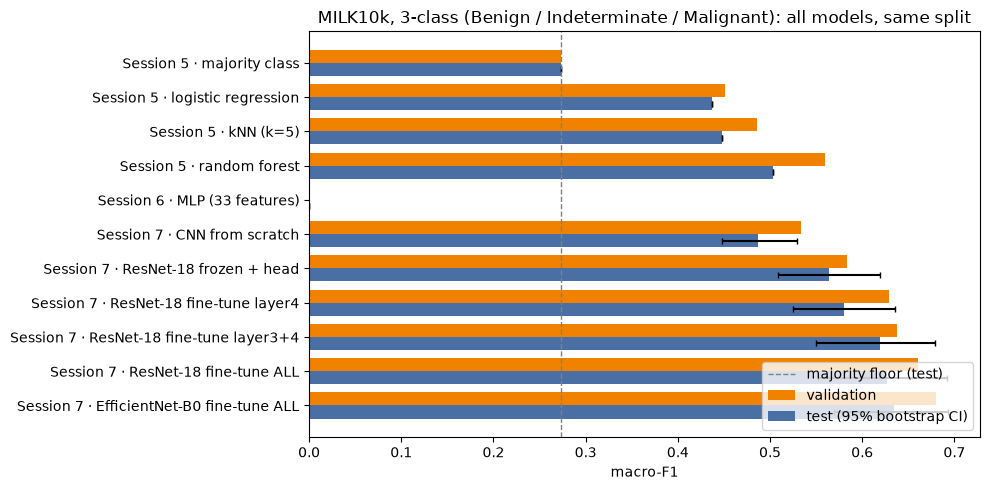

In [24]:
LABELS = {"scratch_cnn": "Session 7 · CNN from scratch",
          "resnet18_frozen_head": "Session 7 · ResNet-18 frozen + head",
          "resnet18_layer4": "Session 7 · ResNet-18 fine-tune layer4",
          "resnet18_layer3_4": "Session 7 · ResNet-18 fine-tune layer3+4",
          "resnet18_full": "Session 7 · ResNet-18 fine-tune ALL"}
if RUN_EFFICIENTNET:
    LABELS["efficientnet_b0_full"] = "Session 7 · EfficientNet-B0 fine-tune ALL"

rows = [{"model": "Session 5 · majority class", "val_f1": results["majority"]["val_f1"], "test_f1": results["majority"]["test_f1"]}]
rows += [{"model": k, "val_f1": v["val_f1"], "test_f1": v["test_f1"]} for k, v in PRIOR.items()]
for k, lab in LABELS.items():
    if k in results and "test_f1" in results[k]:
        r = results[k]
        rows.append({"model": lab, "val_f1": r["val_f1"], "test_f1": r["test_f1"],
                     "test_ci_low": r["test_ci"][0], "test_ci_high": r["test_ci"][1], "params_trained": r["params_trained"],
                     "recall_Benign_test": r["test_recall"][0], "recall_Indeterminate_test": r["test_recall"][1],
                     "recall_Malignant_test": r["test_recall"][2]})
board = pd.DataFrame(rows)
board.to_csv(OUT / "scoreboard.csv", index=False)
display(board.round(3).style.format(precision=3, na_rep="–").background_gradient(subset=["val_f1", "test_f1"], cmap="Oranges"))

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(board)); h = 0.38
if "test_ci_low" in board:
    xerr = np.vstack([np.nan_to_num(board["test_f1"] - board["test_ci_low"]), np.nan_to_num(board["test_ci_high"] - board["test_f1"])])
else:
    xerr = None
ax.barh(y - h/2, board["val_f1"].fillna(0), h, label="validation", color="#F08200")
ax.barh(y + h/2, board["test_f1"].fillna(0), h, label="test (95% bootstrap CI)", color="#4a6fa5", xerr=xerr, capsize=2)
ax.set_yticks(y); ax.set_yticklabels(board["model"]); ax.invert_yaxis()
ax.axvline(results["majority"]["test_f1"], color="gray", ls="--", lw=1, label="majority floor (test)")
ax.set_xlabel("macro-F1"); ax.set_title("MILK10k, 3-class (Benign / Indeterminate / Malignant): all models, same split")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUT / "scoreboard.png", dpi=150); plt.show()

In [25]:
# Seed-to-seed variation of the full fine-tune (needs RUN_SEEDS = True)
seed_names = [k for k in ["resnet18_full", "resnet18_full_seed1", "resnet18_full_seed2"] if k in results and "test_f1" in results[k]]
if len(seed_names) >= 2:
    v = np.array([results[k]["val_f1"] for k in seed_names]); t = np.array([results[k]["test_f1"] for k in seed_names])
    results["seed_summary"] = {"models": seed_names, "val_mean": float(v.mean()), "val_std": float(v.std(ddof=1)),
                               "test_mean": float(t.mean()), "test_std": float(t.std(ddof=1))}
    save_results()
    print(f"full fine-tune over {len(seed_names)} seeds")
    print(f"  validation macro-F1: {v.mean():.3f} +- {v.std(ddof=1):.3f}   (each: {np.round(v, 3).tolist()})")
    print(f"  test macro-F1:       {t.mean():.3f} +- {t.std(ddof=1):.3f}   (each: {np.round(t, 3).tolist()})")
    print("Differences between models smaller than this std are not reliable.")
else:
    print("Run section 4b (RUN_SEEDS = True) to get seed error bars.")

full fine-tune over 3 seeds
  validation macro-F1: 0.646 +- 0.015   (each: [0.66, 0.631, 0.646])
  test macro-F1:       0.622 +- 0.028   (each: [0.627, 0.647, 0.591])
Differences between models smaller than this std are not reliable.


## 6. The best model, chosen on validation

BEST SESSION-7 MODEL (selected on validation): Session 7 · EfficientNet-B0 fine-tune ALL
  validation macro-F1 = 0.680   |   test macro-F1 = 0.635  (95% CI 0.570 to 0.693)
  recall on test: Benign 0.70 · Indeterminate 0.71 · Malignant 0.75
  vs. Session 5 random forest (val 0.56): +0.120 macro-F1 on validation
  trainable parameters: 4,011,391

Note: the validation set has only 17 Indeterminate and the test set 17; differences below ~0.03 are within noise.


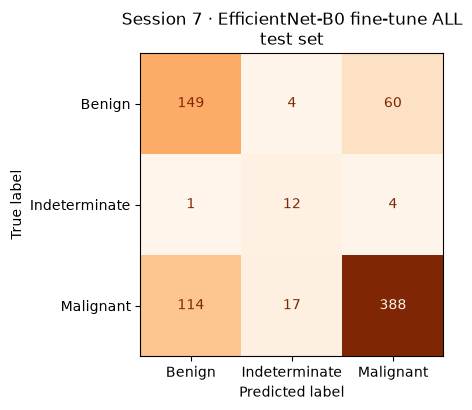

               precision    recall  f1-score   support

       Benign      0.564     0.700     0.625       213
Indeterminate      0.364     0.706     0.480        17
    Malignant      0.858     0.748     0.799       519

     accuracy                          0.733       749
    macro avg      0.595     0.718     0.635       749
 weighted avg      0.764     0.733     0.742       749



In [26]:
s7 = {k: results[k] for k in LABELS if k in results and "test_f1" in results[k]}
best_name = max(s7, key=lambda k: s7[k]["val_f1"])
b = results[best_name]
n_ind_val = int((y_val == 1).sum())
print(f"BEST SESSION-7 MODEL (selected on validation): {LABELS[best_name]}")
print(f"  validation macro-F1 = {b['val_f1']:.3f}   |   test macro-F1 = {b['test_f1']:.3f}  (95% CI {b['test_ci'][0]:.3f} to {b['test_ci'][1]:.3f})")
print(f"  recall on test: Benign {b['test_recall'][0]:.2f} · Indeterminate {b['test_recall'][1]:.2f} · Malignant {b['test_recall'][2]:.2f}")
rf = PRIOR["Session 5 · random forest"]["val_f1"]
print(f"  vs. Session 5 random forest (val {rf}): {b['val_f1'] - rf:+.3f} macro-F1 on validation")
print(f"  trainable parameters: {b['params_trained']:,}")
print()
print(f"Note: the validation set has only {n_ind_val} Indeterminate and the test set {int((y_test == 1).sum())}; differences below ~0.03 are within noise.")

test_pred_best = np.load(OUT / f"{best_name}_test_pred.npy")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred_best, display_labels=CLASSES, cmap="Oranges", ax=ax, colorbar=False)
ax.set_title(f"{LABELS[best_name]}\ntest set"); plt.tight_layout()
plt.savefig(OUT / "best_model_confusion_test.png", dpi=150); plt.show()
print(classification_report(y_test, test_pred_best, target_names=CLASSES, digits=3, zero_division=0))

In [27]:
TARGET_MAL_RECALL = 0.85
if best_name not in prob_fns:
    print("no probabilities available for", best_name)
else:
    pv, pt = prob_fns[best_name]("val"), prob_fns[best_name]("test")
    decide = lambda p, w: (p * torch.tensor([1.0, 1.0, float(w)])).argmax(1)
    rows = []
    for w in [1, 1.25, 1.5, 2, 2.5, 3, 4, 5, 7]:
        pr = decide(pv, w)
        rec = recall_score(y_val, pr, average=None, labels=[0, 1, 2])
        rows.append({"w": w, "val_recall_Benign": rec[0], "val_recall_Indeterminate": rec[1], "val_recall_Malignant": rec[2],
                     "val_macro_F1": f1_score(y_val, pr, average="macro")})
    sweep = pd.DataFrame(rows); display(sweep.round(3))
    ok = sweep[sweep["val_recall_Malignant"] >= TARGET_MAL_RECALL]
    if ok.empty:
        print(f"Target {TARGET_MAL_RECALL} not reached on validation with these weights; nothing applied to test.")
    else:
        w = float(ok.iloc[0]["w"]); pr = decide(pt, w)
        rec = recall_score(y_test, pr, average=None, labels=[0, 1, 2])
        results["thresholded"] = {"model": best_name, "w": w, "target_val_malignant_recall": TARGET_MAL_RECALL,
                                  "test_f1": float(f1_score(y_test, pr, average="macro")), "test_recall": [float(r) for r in rec]}
        save_results()
        print(f"chosen on validation: w = {w}  (val Malignant recall {ok.iloc[0]['val_recall_Malignant']:.2f})")
        print(f"TEST with this rule (scored once): macro-F1 {results['thresholded']['test_f1']:.3f} | recall Benign {rec[0]:.2f} · Indeterminate {rec[1]:.2f} · Malignant {rec[2]:.2f}")
        print(f"vs. plain argmax:                   macro-F1 {b['test_f1']:.3f} | recall Benign {b['test_recall'][0]:.2f} · Indeterminate {b['test_recall'][1]:.2f} · Malignant {b['test_recall'][2]:.2f}")
        print("Report this as a separate decision rule, not as a replacement row; do not tune w on test.")

,w,val_recall_Benign,val_recall_Indeterminate,val_recall_Malignant,val_macro_F1
0,1.00,0.792,0.647,0.763,0.680
1,1.25,0.769,0.588,0.788,0.677
2,1.50,0.759,0.588,0.806,0.691
3,2.00,0.717,0.588,0.846,0.703
4,2.50,0.693,0.588,0.860,0.712
5,3.00,0.670,0.588,0.869,0.716
6,4.00,0.618,0.588,0.894,0.718
7,5.00,0.608,0.529,0.900,0.703
8,7.00,0.561,0.529,0.917,0.703


chosen on validation: w = 2.5  (val Malignant recall 0.86)
TEST with this rule (scored once): macro-F1 0.669 | recall Benign 0.63 · Indeterminate 0.53 · Malignant 0.86
vs. plain argmax:                   macro-F1 0.635 | recall Benign 0.70 · Indeterminate 0.71 · Malignant 0.75
Report this as a separate decision rule, not as a replacement row; do not tune w on test.


In [28]:
from math import sqrt
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

for name in ["efficientnet_b0_full", "resnet18_full"]:
    pred = np.load(OUT / f"{name}_test_pred.npy")
    k = int(((pred == 1) & (y_test.numpy() == 1)).sum()); n = int((y_test == 1).sum())
    lo, hi = wilson(k, n)
    print(f"{name:22s} Indeterminate found {k}/{n} = {k/n:.2f}  (95% interval {lo:.2f} to {hi:.2f})")

efficientnet_b0_full   Indeterminate found 12/17 = 0.71  (95% interval 0.47 to 0.87)
resnet18_full          Indeterminate found 8/17 = 0.47  (95% interval 0.26 to 0.69)


## 7. EfficientNet / DenseNet vs. ResNet — one sentence each

* **DenseNet:** where ResNet *adds* a block's input to its output (`x + F(x)`), DenseNet *concatenates* the feature maps of every earlier layer as input to each new layer, so features are reused directly, with fewer parameters per layer and stronger gradient flow.
* **EfficientNet:** instead of making a ResNet deeper *or* wider *or* fed with larger images by hand, it scales depth, width and input resolution together with one fixed *compound* coefficient, on a base network built from efficient MBConv blocks (with squeeze-and-excitation), reaching ResNet-level accuracy with several times fewer parameters.